# 04. 고유 이벤트 정책과 고장 예측 라벨

기존 03_fault_analysis.ipynb와 `eda_common.py`, `eda_detail.py`의 검증 결과를 활용하여 **새 경로 `data/processed/ml_v1/`**에 구축했습니다. 원본과 기존 EDA 파일·결과는 변경하지 않았습니다. 전체 센서/TTF는 200,000행 청크로 함께 읽고 시각열과 다음 고장 차이를 다시 대조했습니다. 아래 표는 실제 Parquet의 집계이며 모델 학습 결과가 아닙니다.

In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd() if (Path.cwd()/"src").is_dir() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
assert Path(sys.prefix).name.lower()=="phm2018"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.dataset_common import DEST,REPORT,POLICY,FAULTS,SENSORS,HORIZONS,feature_columns,label_columns
summary=json.loads((REPORT/"dataset_summary.json").read_text(encoding="utf-8"))
assert summary["all_checks_passed"]
assert len(summary["tools"])==20,"전체 장비 구축·검증을 먼저 완료하세요."
full=pd.DataFrame(summary["full_counts"])
ready=pd.DataFrame(summary["ready_counts"])
events=pd.DataFrame(summary["fault_events"])
plt.rcParams.update({"font.family":"Malgun Gothic","axes.unicode_minus":False,"figure.dpi":110})
pd.set_option("display.max_columns",30)
def save_figure(fig,name):
    folder=REPORT/"figures";folder.mkdir(exist_ok=True)
    fig.savefig(folder/(name+".png"),dpi=130,bbox_inches="tight")
    plt.show()
print("실행 Python:",sys.executable)
print("데이터 경로:",DEST)

실행 Python: C:\Users\fl27\anaconda3\envs\phm2018\python.exe
데이터 경로: C:\Users\fl27\Documents\ChatGPT\PHM2018-Project\data\processed\ml_v1


## 시간 단위 및 정합성

[PHM Society 공식 설명](https://phmsociety.org/conference/annual-conference-of-the-phm-society/annual-conference-of-the-prognostics-and-health-management-society-2018-b/phm-data-challenge-6/)은 익명화 단위 미공개와 시간의 초 예시를 제시하지만 물리 단위를 확정하지 않습니다. 실제 기록의 최빈 간격은 4이고 TTF는 fault와 같은 좌표 차이입니다. 이것만으로 물리 초를 증명할 수 없습니다.

따라서 **라벨 이름은 h300raw/h600raw/h1800raw**입니다. 각각 5/10/30분으로 부를 수 있는 것은 `time=초`가 확인될 때뿐입니다. 현재 결과를 검증된 물리 분 예측 데이터라고 해석하지 않습니다. 공식 test의 정답은 로컬 파일에 없으며 내부 평가에 넣지 않았습니다.

In [2]:
display(pd.Series(POLICY,name="정책").to_frame())
checks=pd.DataFrame(summary["checks"])
display(checks)
print("전체 센서/TTF 재대조 불일치:",sum(json.loads((REPORT/f"labels_{t}.json").read_text(encoding="utf-8"))["ttf_mismatches"] for t in summary["tools"]))
display(Markdown("원본 fault 1,236행에서 동일 Tool·time·원문 유형의 중복 25행을 제거한 고유 이벤트는 1,211건입니다. 기본 타깃에서는 `[NoWaferID]` 1건을 추가 제외하여 1,210건을 사용합니다. 원본 이력은 그대로 보존했습니다. 센서 동시각 행은 같은 시각 배치의 센서 평균으로 정리했고 Recipe/Stage가 모순된 시각은 격리했습니다."))

,정책
time_unit,raw_unverified
physical_minutes_verified,False
horizons_raw,"[300, 600, 1800]"
feature_windows_raw,"[60, 300]"
max_feature_lookback_raw,600
max_continuity_gap_raw,12
feature_anchor_stride_raw,60
default_event_policy,deduplicate_Tool_time_raw_type_then_exclude_No...
negative_evidence,finite_TTF_matches_next_same_type_event_and_fu...
missing_ttf,NA


,Tool,label_rows,anchor_rows,passed
0,01M01,3119431,218970,True
1,01M02,5103087,345344,True
2,02M01,2864055,200758,True
3,02M02,4141715,294710,True
4,03M01,3431191,243115,True
5,03M02,5059330,359327,True
6,04M01,5096263,362839,True
7,04M02,4449140,301192,True
8,05M01,4759318,339279,True
9,05M02,1897629,136511,True


전체 센서/TTF 재대조 불일치: 0


원본 fault 1,236행에서 동일 Tool·time·원문 유형의 중복 25행을 제거한 고유 이벤트는 1,211건입니다. 기본 타깃에서는 `[NoWaferID]` 1건을 추가 제외하여 1,210건을 사용합니다. 원본 이력은 그대로 보존했습니다. 센서 동시각 행은 같은 시각 배치의 센서 평균으로 정리했고 Recipe/Stage가 모순된 시각은 격리했습니다.

## 라벨 정의와 음성의 근거

각 유형 f1=저압, f2=고압, f3=누출에 대해 다음을 적용합니다.

- 양성 1: 검증된 유한 TTF와 다음 동일 유형 이벤트가 일치하고 `0<TTF<=H`이며, 이벤트 직전까지 연속 관측이 유지된 경우입니다. 이벤트가 마지막 센서 관측보다 최대 12 원시단위 뒤에 있는 경우까지 허용합니다.
- 음성 0: 검증된 유한 `TTF>H`이고 현재부터 H까지 같은 연속 관측 세그먼트인 경우만 부여합니다.
- NA: TTF 결측·모순, 미래 관측 공백·종료, 공정 상태 모순, 모든 고장 시각 자체 등입니다. 누락된 고장 이력의 완전성을 보증하는 정책은 아니므로 제공 이력에 대한 음성임을 명시합니다.
- 연속 세그먼트는 인접 관측 간격 12 원시단위 초과와 모순 시각에서 끊습니다. 음성은 구간 전체, 양성은 확인된 이벤트까지의 연속성을 요구합니다. 고장 시각에는 예측하지 않습니다.
- 통합 any는 3종 중 하나라도 1이면 1, 세 유형 모두 0일 때만 0, 나머지는 NA입니다.

라벨·TTF·이벤트 키·관측 세그먼트 종료 시각은 타깃/품질/분할 메타데이터이며 입력 특징에 포함하지 않습니다.

,fault_code,horizon_raw,rows,positive,negative,unknown
0,any,300,82071907,27104,21586913,60457890
1,any,600,82071907,49268,14377472,67645167
2,any,1800,82071907,105747,6485450,75480710
3,f1,300,82071907,16611,43894566,38160730
4,f1,600,82071907,30026,27822831,54219050
5,f1,1800,82071907,62746,11639721,70369440
6,f2,300,82071907,5815,38866349,43199743
7,f2,600,82071907,10827,23882260,58178820
8,f2,1800,82071907,24277,9404732,72642898
9,f3,300,82071907,4854,28242453,53824600


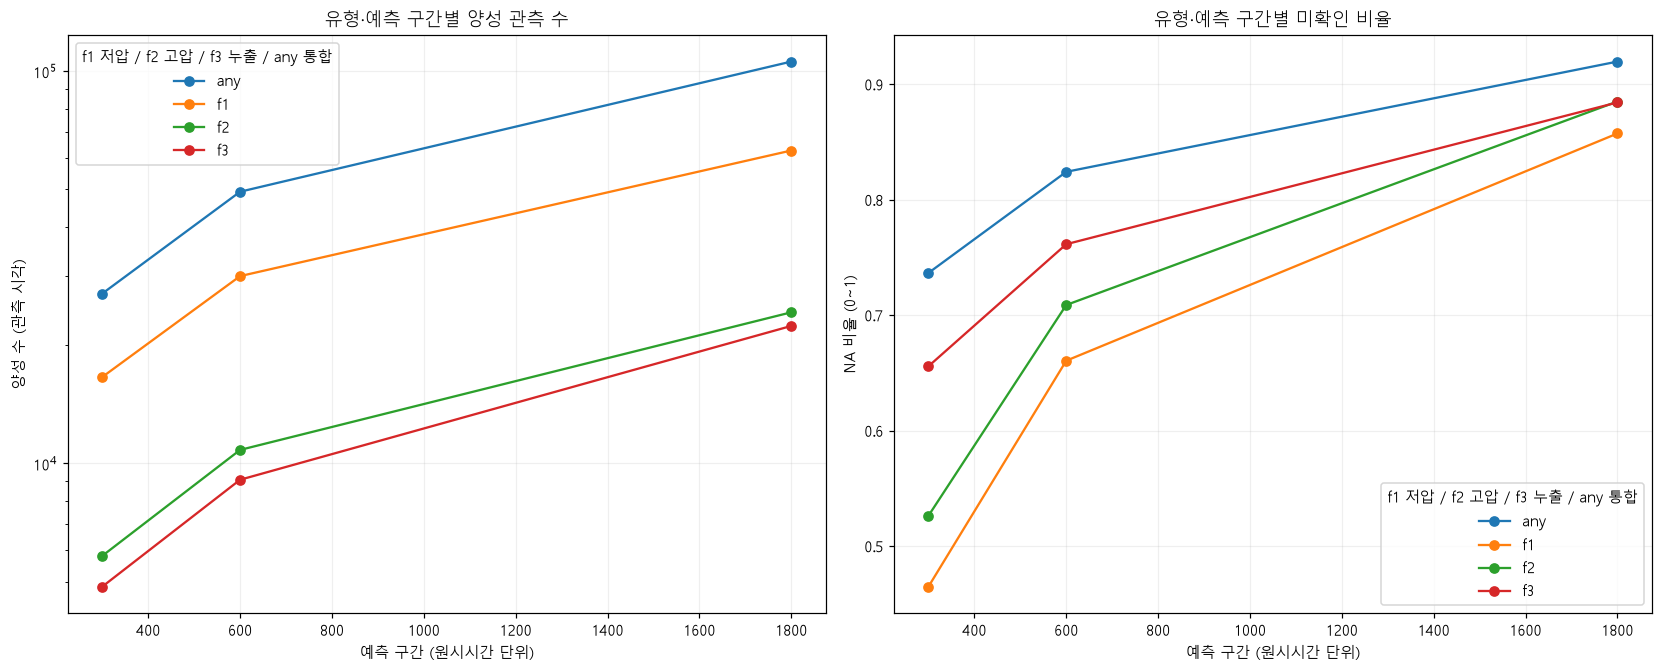

동시각 집계 후 **82,071,907개 관측 시각**에 12개 기본 타깃을 생성했습니다. 표의 수치는 원본 행 수나 고장 이벤트 수가 아닌 정규화 관측 시각 수입니다. 예측 구간이 길수록 연속 관측 요구가 엄격해져 음성 후보가 NA로 바뀔 수 있습니다.

In [3]:
global_counts=full.groupby(["fault_code","horizon_raw"])[["rows","positive","negative","unknown"]].sum().reset_index()
display(global_counts)
assert (global_counts.positive+global_counts.negative+global_counts.unknown==global_counts.rows).all()
fig,axes=plt.subplots(1,2,figsize=(15,6),layout="constrained")
for fault,g in global_counts.groupby("fault_code"):
    axes[0].plot(g.horizon_raw,g.positive,marker="o",label=fault)
    axes[1].plot(g.horizon_raw,g.unknown/g.rows,marker="o",label=fault)
axes[0].set(title="유형·예측 구간별 양성 관측 수",xlabel="예측 구간 (원시시간 단위)",ylabel="양성 수 (관측 시각)",yscale="log")
axes[1].set(title="유형·예측 구간별 미확인 비율",xlabel="예측 구간 (원시시간 단위)",ylabel="NA 비율 (0~1)")
for ax in axes:ax.legend(title="f1 저압 / f2 고압 / f3 누출 / any 통합");ax.grid(alpha=.2)
save_figure(fig,"label_distribution")
display(Markdown(f"동시각 집계 후 **{summary['label_rows']:,}개 관측 시각**에 12개 기본 타깃을 생성했습니다. 표의 수치는 원본 행 수나 고장 이벤트 수가 아닌 정규화 관측 시각 수입니다. 예측 구간이 길수록 연속 관측 요구가 엄격해져 음성 후보가 NA로 바뀔 수 있습니다."))

## `[NoWaferID]` 포함/제외 영향

기본 정책은 태그 제외이며 제공 TTF와 일치합니다. 대안은 태그를 포함한 fault 이력을 우선하여 후보 라벨을 다시 계산합니다. 이 대안은 03M02의 제공 TTF와 충돌하므로 **훈련 타깃에 사용하지 않습니다**. 충돌 구간을 격리하는 경우 추가 NA 수를 함께 제시합니다. 원문 3,489행의 불일치와 동시각 집계 후 충돌 관측 수는 분모가 다를 수 있습니다.

In [4]:
impact=pd.DataFrame(summary["policy_impact"])
display(impact)
event_policy=events.groupby(["fault_code","tagged"]).size().rename("고유 이벤트 수").reset_index()
display(event_policy)
display(Markdown("고유 이벤트 수는 태그 포함 1,211건, 제외 1,210건입니다. 고압은 333건에서 332건으로 바뀝니다. 제공 TTF와의 일치가 확보되는 태그 제외 정책을 기본으로 채택했으며, 태그 포함 대안의 라벨은 별도 `alt_` 컬럼에만 보존합니다."))

,horizon_raw,rows,changed_rows,conflict_rows,include_positive,include_negative,include_unknown,quarantine_extra_unknown
0,300,82071907,75,3482,5890,38866274,43199743,3181
1,600,82071907,150,3482,10977,23882110,58178820,2882
2,1800,82071907,364,3482,24641,9404368,72642898,2241


,fault_code,tagged,고유 이벤트 수
0,f1,False,741
1,f2,False,332
2,f2,True,1
3,f3,False,137


고유 이벤트 수는 태그 포함 1,211건, 제외 1,210건입니다. 고압은 333건에서 332건으로 바뀝니다. 제공 TTF와의 일치가 확보되는 태그 제외 정책을 기본으로 채택했으며, 태그 포함 대안의 라벨은 별도 `alt_` 컬럼에만 보존합니다.

## 공정 상태 분포와 고장 시점의 상태

관측 시각의 Stage=0, Stage>0, 모순 상태를 구분합니다. 고장 상태는 동일 Tool의 고장 시각 이하 마지막 센서 기록을 사용하되 간격이 12 원시단위보다 크면 미확인으로 둡니다. 고장 시각 이후 기록으로 Stage를 채우지 않습니다. Recipe/Stage 범주 크기는 연속 강도가 아닙니다.

,관측 시각 수
state_group,
stage0,2531264
stage_positive,79540643


,관측 시각 수
recipe,
67.0,7717897
3.0,7157182
1.0,5132398
2.0,5071697
143.0,4370446
...,...
103.0,74
117.0,74
86.0,72


state_group,stage0,stage_positive,unknown
fault_code,,,
f1,12,235,494
f2,1,81,250
f3,0,71,66


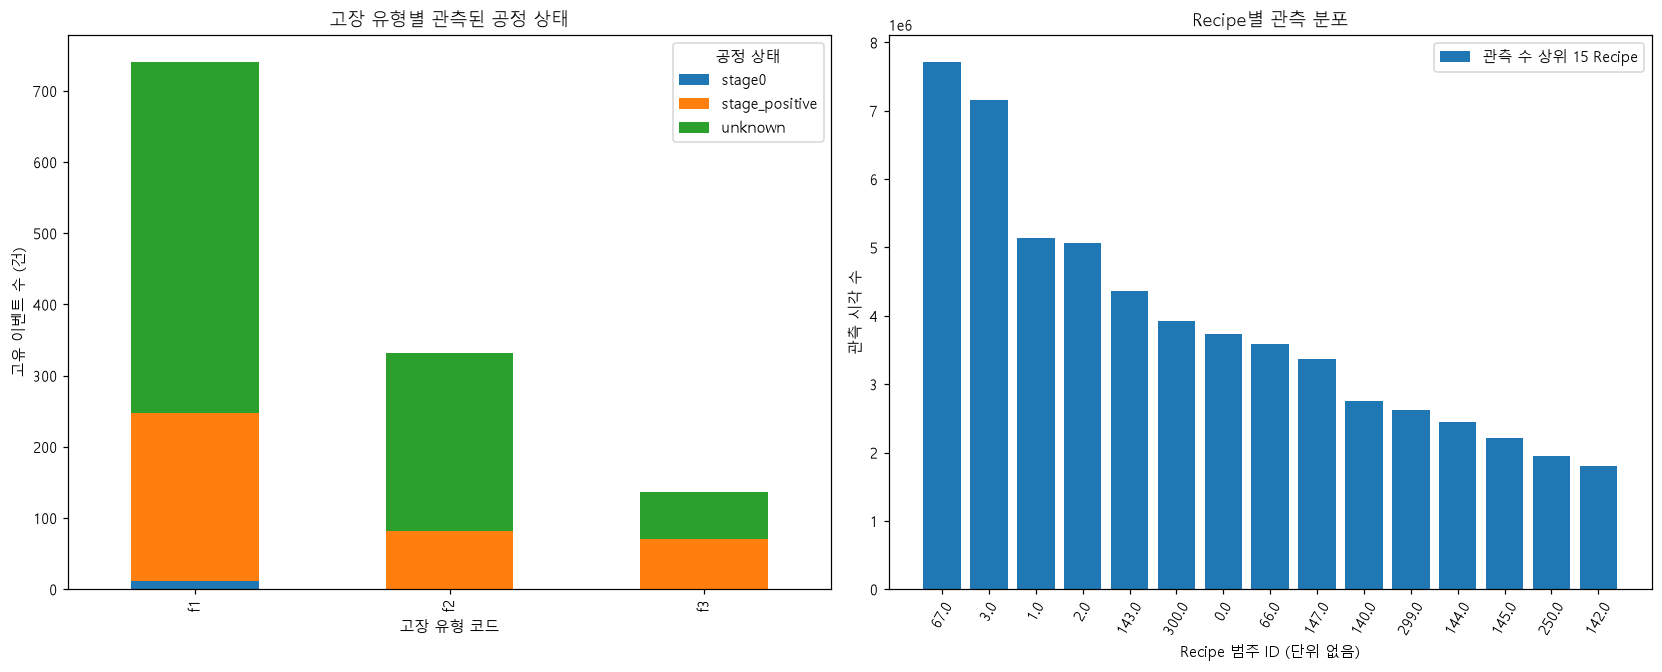

Stage=0을 자동 정상이나 자동 이상으로 분류하지 않았습니다. 전체 상태 데이터와 Stage>0 필터를 적용한 가동 상태 데이터를 같은 원본 분할에서 비교할 수 있습니다. 고장 시각과 센서 기록 사이의 긴 공백 때문에 많은 이벤트의 Stage는 미확인일 수 있습니다.

In [5]:
process=pd.DataFrame(summary["process_distribution"])
display(full.query("fault_code=='any' and horizon_raw==300").groupby("state_group")["rows"].sum().rename("관측 시각 수").to_frame())
display(process.groupby("recipe")["rows"].sum().sort_values(ascending=False).rename("관측 시각 수").to_frame())
event_stage=pd.crosstab(events.loc[~events.tagged,"fault_code"],events.loc[~events.tagged,"state_group"])
display(event_stage)
fig,axes=plt.subplots(1,2,figsize=(15,6),layout="constrained")
event_stage.plot.bar(stacked=True,ax=axes[0]);axes[0].set(title="고장 유형별 관측된 공정 상태",xlabel="고장 유형 코드",ylabel="고유 이벤트 수 (건)");axes[0].legend(title="공정 상태")
top=process.groupby("recipe").rows.sum().nlargest(15)
axes[1].bar(top.index.astype(str),top.values,label="관측 수 상위 15 Recipe")
axes[1].set(title="Recipe별 관측 분포",xlabel="Recipe 범주 ID (단위 없음)",ylabel="관측 시각 수");axes[1].tick_params(axis="x",rotation=60);axes[1].legend()
save_figure(fig,"stage_recipe_distribution")
display(Markdown("Stage=0을 자동 정상이나 자동 이상으로 분류하지 않았습니다. 전체 상태 데이터와 Stage>0 필터를 적용한 가동 상태 데이터를 같은 원본 분할에서 비교할 수 있습니다. 고장 시각과 센서 기록 사이의 긴 공백 때문에 많은 이벤트의 Stage는 미확인일 수 있습니다."))